# Análise de Churn — Telco Customer Churn

Análise exploratória da base de clientes de uma operadora de telecom (7.043 clientes, 21 colunas) para entender quem cancela o serviço (`Churn = Yes`).

1. Tabelas de distribuição de frequência (contínuas e categóricas)
2. Medidas de posição e dispersão
3. Taxa de churn por variável
4. Modelo baseline de previsão

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.append(os.path.abspath('../src'))
from estatistica import (calcular_classes, criar_tabela_frequencia,
                         criar_tabela_frequencia_categorica, formatar_tabela,
                         medidas_resumo, taxa_churn)

df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
# TotalCharges vem como texto: 11 clientes com tenure 0 têm o campo vazio
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# SeniorCitizen é binária (0/1), não contínua
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# Estilo dos gráficos: uma cor por série, grade discreta
AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#8a8a85'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e4e4e0',
    'grid.linewidth': 0.8,
})

## Variáveis disponíveis

In [2]:
continuas = df.select_dtypes(include='number').columns.tolist()
categoricas = [c for c in df.columns if c not in continuas and c != 'customerID']

print('VARIÁVEIS NUMÉRICAS (tabela com intervalos de classe):')
for col in continuas:
    print(f'   -> {col}')
print('\nVARIÁVEIS CATEGÓRICAS (tabela de frequência simples):')
for col in categoricas:
    print(f'   -> {col}')

VARIÁVEIS NUMÉRICAS (tabela com intervalos de classe):
   -> tenure
   -> MonthlyCharges
   -> TotalCharges

VARIÁVEIS CATEGÓRICAS (tabela de frequência simples):
   -> gender
   -> SeniorCitizen
   -> Partner
   -> Dependents
   -> PhoneService
   -> MultipleLines
   -> InternetService
   -> OnlineSecurity
   -> OnlineBackup
   -> DeviceProtection
   -> TechSupport
   -> StreamingTV
   -> StreamingMovies
   -> Contract
   -> PaperlessBilling
   -> PaymentMethod
   -> Churn


## 1. Distribuição de frequência — variáveis contínuas

Intervalos de classe pela regra de Sturges, com o histograma desenhado sobre as mesmas classes da tabela.

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (tenure),,,,,,
0.00 |--- 5.14,2.57,1371,0.1947,19.47%,1371,19.47%
5.14 |--- 10.29,7.71,599,0.0850,8.50%,1970,27.97%
10.29 |--- 15.43,12.86,500,0.0710,7.10%,2470,35.07%
15.43 |--- 20.57,18.00,408,0.0579,5.79%,2878,40.86%
20.57 |--- 25.71,23.14,411,0.0584,5.84%,3289,46.70%
25.71 |--- 30.86,28.29,352,0.0500,5.00%,3641,51.70%
30.86 |--- 36.00,33.43,351,0.0498,4.98%,3992,56.68%
36.00 |--- 41.14,38.57,364,0.0517,5.17%,4356,61.85%
41.14 |--- 46.29,43.71,316,0.0449,4.49%,4672,66.34%


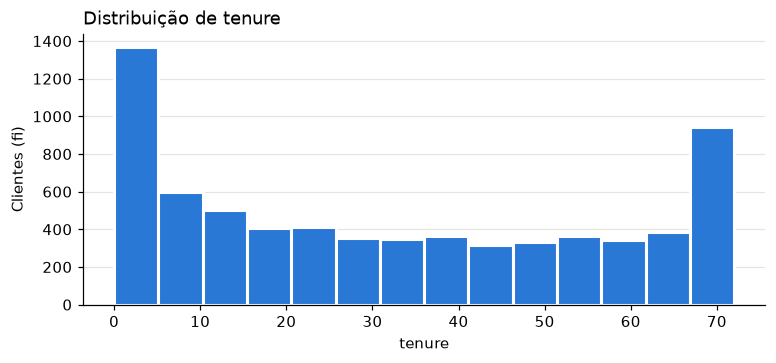

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (MonthlyCharges),,,,,,
18.25 |--- 25.43,21.84,1511,0.2145,21.45%,1511,21.45%
25.43 |--- 32.61,29.02,179,0.0254,2.54%,1690,24.00%
32.61 |--- 39.79,36.20,143,0.0203,2.03%,1833,26.03%
39.79 |--- 46.96,43.38,311,0.0442,4.42%,2144,30.44%
46.96 |--- 54.14,50.55,372,0.0528,5.28%,2516,35.72%
54.14 |--- 61.32,57.73,478,0.0679,6.79%,2994,42.51%
61.32 |--- 68.50,64.91,280,0.0398,3.98%,3274,46.49%
68.50 |--- 75.68,72.09,750,0.1065,10.65%,4024,57.13%
75.68 |--- 82.86,79.27,614,0.0872,8.72%,4638,65.85%


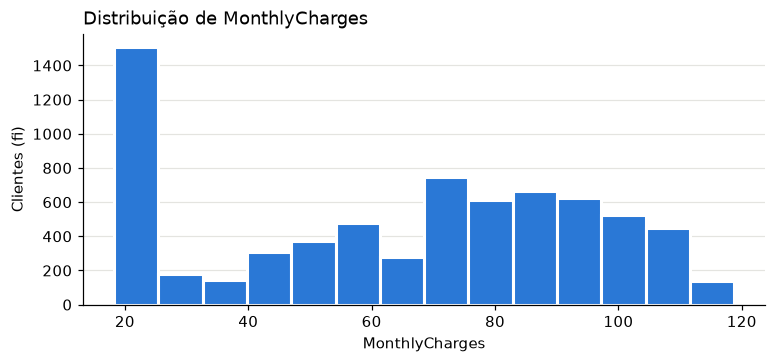

,Ponto Médio (xi),Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Classes (TotalCharges),,,,,,
18.80 |--- 637.80,328.30,2269,0.3227,32.27%,2269,32.27%
"637.80 |--- 1,256.80",947.30,1026,0.1459,14.59%,3295,46.86%
"1,256.80 |--- 1,875.80","1,566.30",783,0.1113,11.13%,4078,57.99%
"1,875.80 |--- 2,494.80","2,185.30",449,0.0639,6.39%,4527,64.38%
"2,494.80 |--- 3,113.80","2,804.30",379,0.0539,5.39%,4906,69.77%
"3,113.80 |--- 3,732.80","3,423.30",336,0.0478,4.78%,5242,74.54%
"3,732.80 |--- 4,351.80","4,042.30",328,0.0466,4.66%,5570,79.21%
"4,351.80 |--- 4,970.80","4,661.30",312,0.0444,4.44%,5882,83.65%
"4,970.80 |--- 5,589.80","5,280.30",260,0.0370,3.70%,6142,87.34%


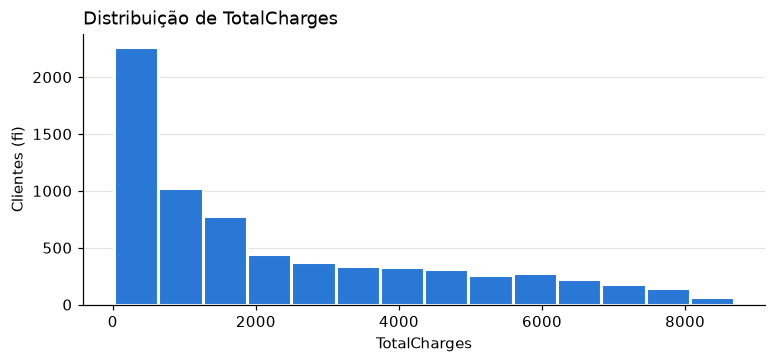

In [3]:
for coluna in continuas:
    tabela = criar_tabela_frequencia(df, coluna)
    display(formatar_tabela(tabela))

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.hist(df[coluna].dropna(), bins=calcular_classes(df[coluna]), color=AZUL,
            edgecolor='white', linewidth=2)
    ax.set_title(f'Distribuição de {coluna}', loc='left')
    ax.set_xlabel(coluna)
    ax.set_ylabel('Clientes (fi)')
    ax.grid(axis='x', visible=False)
    plt.show()

## 2. Distribuição de frequência — variáveis categóricas

In [4]:
for coluna in categoricas:
    display(formatar_tabela(criar_tabela_frequencia_categorica(df, coluna)))

,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
gender,,,,,
Male,3555,0.5048,50.48%,3555,50.48%
Female,3488,0.4952,49.52%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
SeniorCitizen,,,,,
No,5901,0.8379,83.79%,5901,83.79%
Yes,1142,0.1621,16.21%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Partner,,,,,
No,3641,0.5170,51.70%,3641,51.70%
Yes,3402,0.4830,48.30%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Dependents,,,,,
No,4933,0.7004,70.04%,4933,70.04%
Yes,2110,0.2996,29.96%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
PhoneService,,,,,
Yes,6361,0.9032,90.32%,6361,90.32%
No,682,0.0968,9.68%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
MultipleLines,,,,,
No,3390,0.4813,48.13%,3390,48.13%
Yes,2971,0.4218,42.18%,6361,90.32%
No phone service,682,0.0968,9.68%,7043,100.00%


... (7 outputs left out)

,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Contract,,,,,
Month-to-month,3875,0.5502,55.02%,3875,55.02%
Two year,1695,0.2407,24.07%,5570,79.09%
One year,1473,0.2091,20.91%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
PaperlessBilling,,,,,
Yes,4171,0.5922,59.22%,4171,59.22%
No,2872,0.4078,40.78%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
PaymentMethod,,,,,
Electronic check,2365,0.3358,33.58%,2365,33.58%
Mailed check,1612,0.2289,22.89%,3977,56.47%
Bank transfer (automatic),1544,0.2192,21.92%,5521,78.39%
Credit card (automatic),1522,0.2161,21.61%,7043,100.00%


,Frequência Absoluta (fi),Frequência Relativa (fr),Fr (%),Freq. Acumulada (Fi),Fr Acumulada (%)
Churn,,,,,
No,5174,0.7346,73.46%,5174,73.46%
Yes,1869,0.2654,26.54%,7043,100.00%


## 3. Medidas de posição e dispersão

In [5]:
resumo = pd.DataFrame({c: medidas_resumo(df[c]) for c in continuas})
display(resumo.style.format('{:,.2f}'))

,tenure,MonthlyCharges,TotalCharges
Média,32.37,64.76,"2,283.30"
Mediana,29.00,70.35,"1,397.47"
Moda,1.00,20.05,20.20
Desvio Padrão,24.56,30.09,"2,266.77"
Coef. Variação (%),75.87,46.46,99.28
Mínimo,0.00,18.25,18.80
Q1,9.00,35.50,401.45
Q3,55.00,89.85,"3,794.74"
Máximo,72.00,118.75,"8,684.80"
Amplitude Interquartil,46.00,54.35,"3,393.29"


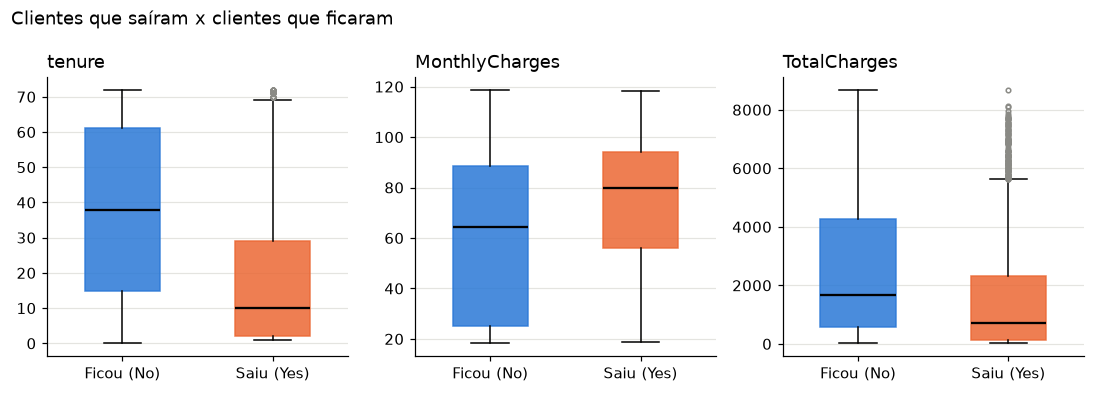

In [6]:
fig, axes = plt.subplots(1, len(continuas), figsize=(10, 3.6))
for ax, coluna in zip(axes, continuas):
    grupos = [df.loc[df['Churn'] == g, coluna].dropna() for g in ('No', 'Yes')]
    caixas = ax.boxplot(grupos, patch_artist=True, widths=0.5,
                        medianprops={'color': 'black', 'linewidth': 1.5},
                        flierprops={'markersize': 3, 'markeredgecolor': CINZA})
    for caixa, cor in zip(caixas['boxes'], (AZUL, LARANJA)):
        caixa.set(facecolor=cor, edgecolor=cor, alpha=0.85)
    ax.set_xticks([1, 2], ['Ficou (No)', 'Saiu (Yes)'])
    ax.set_title(coluna, loc='left')
    ax.grid(axis='x', visible=False)
fig.suptitle('Clientes que saíram x clientes que ficaram', x=0.01, ha='left')
fig.tight_layout()
plt.show()

## 4. Taxa de churn por variável

A linha tracejada é a taxa geral da base. Barras acima dela indicam grupos de maior risco.

Taxa geral de churn: 26.5%


,Clientes,Churn (%)
Contract,,
Month-to-month,3875,42.7%
One year,1473,11.3%
Two year,1695,2.8%


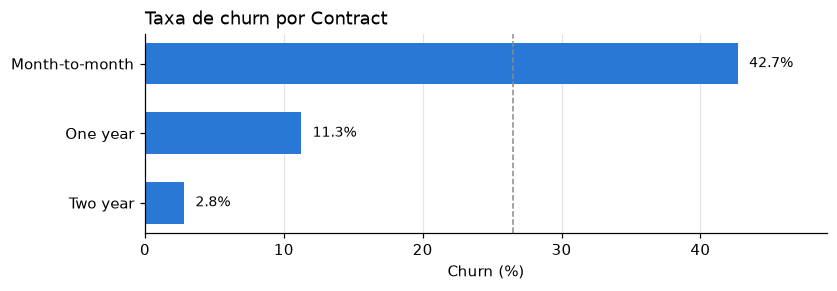

,Clientes,Churn (%)
InternetService,,
Fiber optic,3096,41.9%
DSL,2421,19.0%
No,1526,7.4%


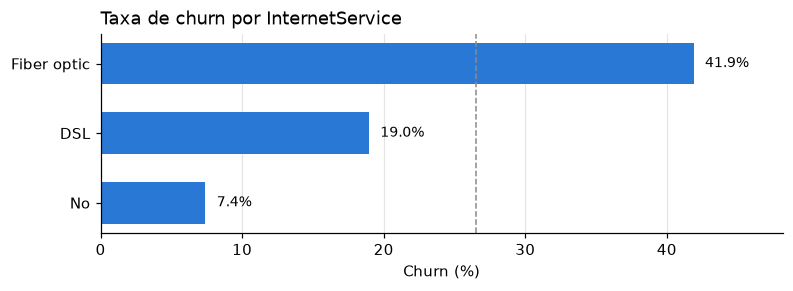

,Clientes,Churn (%)
PaymentMethod,,
Electronic check,2365,45.3%
Mailed check,1612,19.1%
Bank transfer (automatic),1544,16.7%
Credit card (automatic),1522,15.2%


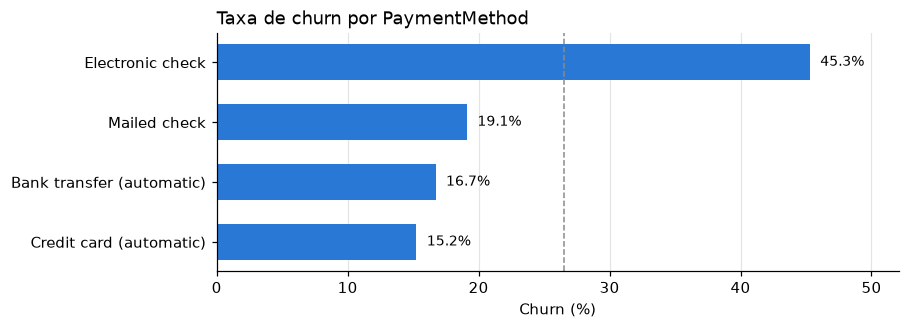

,Clientes,Churn (%)
Faixa de tenure,,
0.00 |--- 5.14,1371,54.3%
5.14 |--- 10.29,599,37.4%
10.29 |--- 15.43,500,33.6%
15.43 |--- 20.57,408,28.2%
20.57 |--- 25.71,411,25.1%
25.71 |--- 30.86,352,20.2%
30.86 |--- 36.00,351,21.7%
36.00 |--- 41.14,364,21.7%
41.14 |--- 46.29,316,16.8%


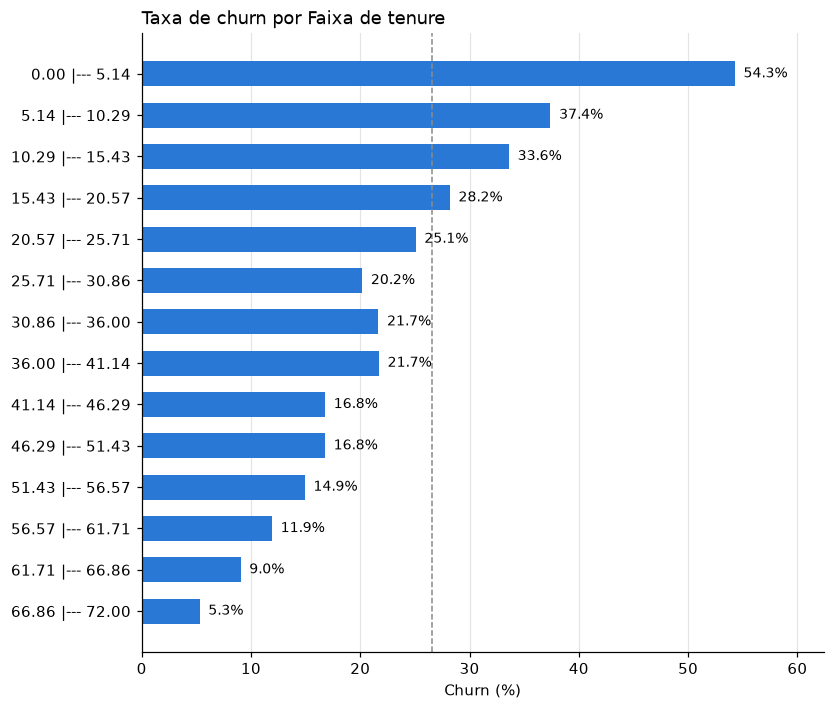

In [7]:
taxa_geral = (df['Churn'] == 'Yes').mean() * 100
print(f'Taxa geral de churn: {taxa_geral:.1f}%')

faixas_tenure = criar_tabela_frequencia(df, 'tenure').index
df_faixas = df.assign(**{'Faixa de tenure': pd.cut(df['tenure'], bins=calcular_classes(df['tenure']),
                                                   right=False, labels=faixas_tenure)})

for coluna in ['Contract', 'InternetService', 'PaymentMethod', 'Faixa de tenure']:
    tabela = taxa_churn(df_faixas, coluna)
    if coluna == 'Faixa de tenure':
        tabela = tabela.sort_index()  # faixas seguem a ordem natural
    display(tabela.style.format({'Churn (%)': '{:.1f}%'}))

    fig, ax = plt.subplots(figsize=(8, 0.45 * len(tabela) + 1))
    ax.barh(tabela.index.astype(str), tabela['Churn (%)'], color=AZUL, height=0.6)
    ax.invert_yaxis()
    ax.axvline(taxa_geral, color=CINZA, linestyle='--', linewidth=1)
    for i, v in enumerate(tabela['Churn (%)']):
        ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_xlim(0, tabela['Churn (%)'].max() * 1.15)
    ax.set_xlabel('Churn (%)')
    ax.set_title(f'Taxa de churn por {coluna}', loc='left')
    ax.grid(axis='y', visible=False)
    plt.show()

## 5. Modelo baseline de previsão

Regressão logística como ponto de partida. As classes são desbalanceadas (cerca de 26% de churn), então:

- o split de treino/teste é estratificado;
- o modelo usa `class_weight='balanced'`;
- a avaliação usa recall, F1 e ROC-AUC. A acurácia sozinha engana: um modelo que sempre responde "No" já acerta cerca de 73%.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=['customerID', 'Churn'])
X['TotalCharges'] = X['TotalCharges'].fillna(0)  # tenure 0: ainda não houve cobrança
y = (df['Churn'] == 'Yes').astype(int)
categoricas_X = [c for c in categoricas if c != 'Churn']

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

modelo = make_pipeline(
    ColumnTransformer([
        ('num', StandardScaler(), continuas),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas_X),
    ]),
    LogisticRegression(max_iter=1000, class_weight='balanced'),
)
modelo.fit(X_treino, y_treino)

prob_teste = modelo.predict_proba(X_teste)[:, 1]
print(f'Acurácia de sempre prever "No": {1 - y_teste.mean():.3f}\n')
print(classification_report(y_teste, modelo.predict(X_teste),
                            target_names=['Ficou (No)', 'Saiu (Yes)'], digits=3))
print(f'ROC-AUC: {roc_auc_score(y_teste, prob_teste):.3f}')

Acurácia de sempre prever "No": 0.735

              precision    recall  f1-score   support

  Ficou (No)      0.909     0.733     0.812      1294
  Saiu (Yes)      0.519     0.797     0.628       467

    accuracy                          0.750      1761
   macro avg      0.714     0.765     0.720      1761
weighted avg      0.806     0.750     0.763      1761

ROC-AUC: 0.846


In [9]:
# Variáveis que mais pesam no modelo (coeficientes padronizados)
nomes = modelo[0].get_feature_names_out()
coeficientes = pd.Series(modelo[-1].coef_[0], index=nomes).sort_values()
display(pd.concat([coeficientes.head(5), coeficientes.tail(5)])
          .rename('Coeficiente').to_frame()
          .style.format('{:+.3f}'))

,Coeficiente
num__tenure,-1.161
cat__Contract_Two year,-0.733
num__MonthlyCharges,-0.666
cat__InternetService_DSL,-0.593
cat__PaperlessBilling_No,-0.271
cat__StreamingTV_Yes,+0.246
cat__StreamingMovies_Yes,+0.291
num__TotalCharges,+0.521
cat__Contract_Month-to-month,+0.648
cat__InternetService_Fiber optic,+0.688
